
--- Baseline Model Evaluation Metrics ---
Accuracy:  0.9651
Precision: 0.8980
Recall:    0.8661
F1-Score:  0.8818
ROC-AUC:   0.9895

5-Fold Stratified CV F1-Scores: [0.8733, 0.8636, 0.8502, 0.8637, 0.87]
Mean CV F1-Score: 0.8642 (+/- 0.0079)

Executing GridSearchCV...
Best Grid Parameters: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 50}
Best Grid Cross-Validation F1-Score: 0.8665

Executing RandomizedSearchCV...
Best Random Parameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 16}
Best Random Cross-Validation F1-Score: 0.8645

Comparative Model Performance:
   Metric  Baseline Model  Tuned Model (RandomSearch)
 Accuracy        0.965108                    0.966319
Precision        0.897993                    0.898839
   Recall        0.866129                    0.874194
 F1-Score        0.881773                    0.886345
  ROC-AUC        0.989514                    0.990626

Experiment 10 Completed Successfully


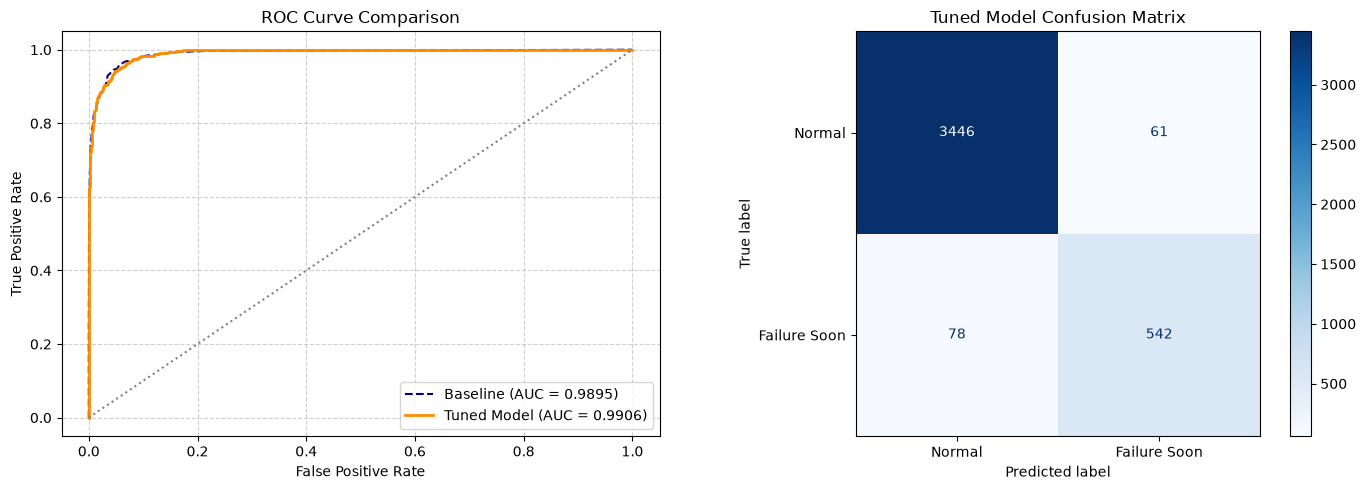

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay
)


# Load C-MAPSS turbofan dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

# Compute Remaining Useful Life (RUL) and binary maintenance target
df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

# Feature selection: operational cycle and active degradation sensors
features = ["cycle", "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", 
            "sensor_9", "sensor_11", "sensor_12", "sensor_13", "sensor_14", 
            "sensor_15", "sensor_17", "sensor_20", "sensor_21"]

X = df[features]
y = df["failure_soon"]

# Stratified split to preserve target class balance (15% failure soon vs 85% normal)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Baseline Model Training & Comprehensive Evaluation
baseline_rf = RandomForestClassifier(n_estimators=50, random_state=42)
baseline_rf.fit(X_train_scaled, y_train)

y_pred_base = baseline_rf.predict(X_test_scaled)
y_prob_base = baseline_rf.predict_proba(X_test_scaled)[:, 1]

acc_base = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base)
rec_base = recall_score(y_test, y_pred_base)
f1_base = f1_score(y_test, y_pred_base)
auc_base = roc_auc_score(y_test, y_prob_base)

print("\n--- Baseline Model Evaluation Metrics ---")
print(f"Accuracy:  {acc_base:.4f}")
print(f"Precision: {prec_base:.4f}")
print(f"Recall:    {rec_base:.4f}")
print(f"F1-Score:  {f1_base:.4f}")
print(f"ROC-AUC:   {auc_base:.4f}")

# 2. 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(baseline_rf, X_train_scaled, y_train, cv=cv, scoring='f1')
print(f"\n5-Fold Stratified CV F1-Scores: {cv_scores.round(4)}")
print(f"Mean CV F1-Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# 3. Hyperparameter Tuning via GridSearchCV
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15],
    'min_samples_split': [2, 5]
}

print("\nExecuting GridSearchCV...")
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)
best_grid_rf = grid_search.best_estimator_
print("Best Grid Parameters:", grid_search.best_params_)
print(f"Best Grid Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

# 4. Hyperparameter Tuning via RandomizedSearchCV
param_dist = {
    'n_estimators': [50, 75, 100, 125],
    'max_depth': [8, 12, 16, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

print("\nExecuting RandomizedSearchCV...")
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=8,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)
best_random_rf = random_search.best_estimator_
print("Best Random Parameters:", random_search.best_params_)
print(f"Best Random Cross-Validation F1-Score: {random_search.best_score_:.4f}")

# 5. Comparative Evaluation on Held-out Test Set
y_pred_tuned = best_random_rf.predict(X_test_scaled)
y_prob_tuned = best_random_rf.predict_proba(X_test_scaled)[:, 1]

acc_tuned = accuracy_score(y_test, y_pred_tuned)
prec_tuned = precision_score(y_test, y_pred_tuned)
rec_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline Model": [acc_base, prec_base, rec_base, f1_base, auc_base],
    "Tuned Model (RandomSearch)": [acc_tuned, prec_tuned, rec_tuned, f1_tuned, auc_tuned]
})
print("\nComparative Model Performance:")
print(comparison_df.to_string(index=False))

# 6. Visualization: ROC Curve & Confusion Matrix
fpr_base, tpr_base, _ = roc_curve(y_test, y_prob_base)
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_prob_tuned)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot ROC Curves
axes[0].plot(fpr_base, tpr_base, color='navy', linestyle='--', label=f'Baseline (AUC = {auc_base:.4f})')
axes[0].plot(fpr_tuned, tpr_tuned, color='darkorange', lw=2, label=f'Tuned Model (AUC = {auc_tuned:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve Comparison')
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot Confusion Matrix of Tuned Model
cm = confusion_matrix(y_test, y_pred_tuned)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Failure Soon"])
disp.plot(cmap="Blues", ax=axes[1], values_format='d')
axes[1].set_title("Tuned Model Confusion Matrix")

plt.show()

print("Experiment 10 Completed Successfully")